# 02 — Algorithmes de Compression : 6 techniques × 10 capteurs (v5, corrigée)

**Compression Adaptative de Signaux Physiologiques Multi-Capteurs par Sélection Dynamique
d'Algorithme via Métaheuristique**

## Correspondance avec le cahier des charges du professeur

| Exigence | Où c'est traité ici |
|---|---|
| Sélection selon **seuil** | Section 11 — écarts de ratio/PRD entre algorithmes selon seuils de complexité du signal |
| Sélection selon **taille** | Section 11 — preuve empirique : Huffman devient contre-productif (ratio < 1) sur les petits segments (wrist EDA/TEMP, 20 échantillons) à cause du coût fixe du codebook |
| Sélection selon **séquence** | Traité dans le notebook 03 (métaheuristique) — comparaison au segment précédent dans le flux |
| **Multi-capteurs** réel | 10 canaux : chest_ACC/ECG/EMG/EDA/Temp/Resp + wrist_ACC/BVP/EDA/TEMP |
| Dataset volumineux (1-2 Go) | WESAD, 2.1 Go, 13.8 Go de données brutes disponibles pour tous les sujets |
| Comparaison entre algorithmes | Section 9 — heatmaps 10 signaux × 6 algorithmes |
| Vue / proposition personnelle | Sélecteur multi-critères + métaheuristique (notebook 03) |

## Ce qui a été corrigé par rapport à v4

**Bug 1 (déjà corrigé en v4)** : segments trop courts pour le niveau de décomposition DWT demandé
→ niveau adapté automatiquement via `pywt.dwt_max_level`.

**Bug 2 (corrigé ici)** : le seuillage DWT s'appliquait aussi au coefficient d'approximation
(`cA`, qui porte la valeur moyenne globale du signal) — ce qui faussait la reconstruction même
sur des signaux parfaitement stables (ex. PRD de 10% sur `chest_Temp`, un signal quasi-constant).
**Correction** : seul le coefficient d'approximation est préservé intact ; le seuillage ne
s'applique qu'aux coefficients de détail (`cD`).

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, pickle, zlib, heapq
from collections import Counter
import numpy as np

BASE = '/content/drive/MyDrive/Projet_Compression_WESAD'
file_path = f'{BASE}/1_Data_Raw/WESAD/S2/S2.pkl'

with open(file_path, 'rb') as f:
    s2_data = pickle.load(f, encoding='latin1')

print("Chest :", list(s2_data['signal']['chest'].keys()))
print("Wrist :", list(s2_data['signal']['wrist'].keys()))


Mounted at /content/drive
Chest : ['ACC', 'ECG', 'EMG', 'EDA', 'Temp', 'Resp']
Wrist : ['ACC', 'BVP', 'EDA', 'TEMP']


## Segmentation des 10 canaux (chest + wrist)

**Méthodologie de segmentation** — trois choix à justifier explicitement, comme demandé par le prof :

**1. Fenêtres de 5 secondes, non chevauchantes.** Une fenêtre de 5s est un compromis délibéré : assez longue pour capturer plusieurs cycles cardiaques complets sur l'ECG (fréquence cardiaque typique 60-100 bpm → 5-8 battements par fenêtre, suffisant pour une décomposition en ondelettes significative), mais assez courte pour rester représentative d'un état physiologique local (le signal peut évoluer vite lors d'une transition repos→stress). Les fenêtres sont **non chevauchantes** pour que chaque échantillon de signal ne soit compressé qu'une seule fois — un chevauchement gonflerait artificiellement le volume de données "traité" sans bénéfice réel, ce qui irait à l'encontre de la remarque du prof sur le volume du dataset.

**2. Une durée fixe en secondes, pas un nombre fixe d'échantillons.** Comme les capteurs RespiBAN (700 Hz) et Empatica E4 (4/32/64 Hz selon le canal) n'ont pas la même fréquence d'échantillonnage, fixer `window_sec=5` et calculer `win_len = fs * window_sec` par canal garantit que **chaque segment représente la même durée physique** (5 secondes), quel que soit le capteur — condition nécessaire pour que le sélecteur compare des segments réellement comparables entre eux (voir notebook 03).

**3. Segmentation indépendante par canal, alignée en indices (pas en timestamps).** Chaque canal est segmenté séparément avec sa propre fréquence, mais le **numéro de segment** (segment i du canal A correspond à la même fenêtre temporelle que le segment i du canal B) reste implicitement synchronisé car tous les canaux d'un même sujet partagent la même origine temporelle dans le fichier WESAD `.pkl`.

In [ ]:
CHANNELS_ALL = [
    {'name': 'chest_ACC',  'device': 'chest', 'key': 'ACC',  'fs': 700, 'multi_axis': True},
    {'name': 'chest_ECG',  'device': 'chest', 'key': 'ECG',  'fs': 700, 'multi_axis': False},
    {'name': 'chest_EMG',  'device': 'chest', 'key': 'EMG',  'fs': 700, 'multi_axis': False},
    {'name': 'chest_EDA',  'device': 'chest', 'key': 'EDA',  'fs': 700, 'multi_axis': False},
    {'name': 'chest_Temp', 'device': 'chest', 'key': 'Temp', 'fs': 700, 'multi_axis': False},
    {'name': 'chest_Resp', 'device': 'chest', 'key': 'Resp', 'fs': 700, 'multi_axis': False},
    {'name': 'wrist_ACC',  'device': 'wrist', 'key': 'ACC',  'fs': 32,  'multi_axis': True},
    {'name': 'wrist_BVP',  'device': 'wrist', 'key': 'BVP',  'fs': 64,  'multi_axis': False},
    {'name': 'wrist_EDA',  'device': 'wrist', 'key': 'EDA',  'fs': 4,   'multi_axis': False},
    {'name': 'wrist_TEMP', 'device': 'wrist', 'key': 'TEMP', 'fs': 4,   'multi_axis': False},
]

def get_signal_1d(data, ch):
    raw = data['signal'][ch['device']][ch['key']]
    return np.linalg.norm(raw, axis=1) if ch['multi_axis'] else raw.flatten()

def segment_signal(signal, fs, window_sec=5):
    win_len = int(fs * window_sec)
    n_windows = len(signal) // win_len
    return [signal[i*win_len:(i+1)*win_len] for i in range(n_windows)]

SIGNALS = {}
for ch in CHANNELS_ALL:
    sig = get_signal_1d(s2_data, ch)
    segs = segment_signal(sig, ch['fs'], window_sec=5)
    SIGNALS[ch['name']] = {'segments': segs, 'fs': ch['fs']}
    print(f"{ch['name']:12s} : {len(segs):4d} segments de {ch['fs']*5} échantillons")


chest_ACC    : 1215 segments de 3500 échantillons
chest_ECG    : 1215 segments de 3500 échantillons
chest_EMG    : 1215 segments de 3500 échantillons
chest_EDA    : 1215 segments de 3500 échantillons
chest_Temp   : 1215 segments de 3500 échantillons
chest_Resp   : 1215 segments de 3500 échantillons
wrist_ACC    : 1215 segments de 160 échantillons
wrist_BVP    : 1215 segments de 320 échantillons
wrist_EDA    : 1215 segments de 20 échantillons
wrist_TEMP   : 1215 segments de 20 échantillons


## 1. RLE — répétition

In [ ]:
def compress_rle(segment, precision=3):
    arr = np.round(np.asarray(segment, dtype=np.float32), precision)
    values, counts = [], []
    prev, count = arr[0], 1
    for x in arr[1:]:
        if x == prev:
            count += 1
        else:
            values.append(prev); counts.append(count)
            prev, count = x, 1
    values.append(prev); counts.append(count)
    values = np.array(values, dtype=np.float32)
    counts = np.array(counts, dtype=np.uint16)
    n_pairs = len(values)
    payload = values.tobytes() + counts.tobytes()
    return zlib.compress(payload), n_pairs

def decompress_rle(compressed, n_pairs):
    raw = zlib.decompress(compressed)
    values = np.frombuffer(raw[:n_pairs*4], dtype=np.float32)
    counts = np.frombuffer(raw[n_pairs*4:], dtype=np.uint16)
    return np.repeat(values, counts)


## 2. LZ77 (via zlib) — dictionnaire / motifs répétés

In [ ]:
def compress_lz77(segment):
    raw = np.asarray(segment, dtype=np.float32).tobytes()
    return zlib.compress(raw, level=9)

def decompress_lz77(compressed):
    return np.frombuffer(zlib.decompress(compressed), dtype=np.float32)


## 3. Huffman (Python pur) — codage entropique générique

In [ ]:
def build_huffman_codebook(symbols):
    freq = Counter(symbols)
    heap = [[weight, [symbol, ""]] for symbol, weight in freq.items()]
    heapq.heapify(heap)
    if len(heap) == 1:
        return {heap[0][1][0]: "0"}
    while len(heap) > 1:
        lo = heapq.heappop(heap); hi = heapq.heappop(heap)
        for pair in lo[1:]: pair[1] = '0' + pair[1]
        for pair in hi[1:]: pair[1] = '1' + pair[1]
        heapq.heappush(heap, [lo[0] + hi[0]] + lo[1:] + hi[1:])
    return {s: c for s, c in heap[0][1:]}

def compress_huffman(segment, precision=3):
    arr = np.round(np.asarray(segment, dtype=np.float32), precision)
    symbols = arr.tolist()
    codebook = build_huffman_codebook(symbols)
    bitstring = ''.join(codebook[s] for s in symbols)
    padding = (8 - len(bitstring) % 8) % 8
    bitstring += '0' * padding
    encoded = bytearray(int(bitstring[i:i+8], 2) for i in range(0, len(bitstring), 8))
    payload = {'codebook': pickle.dumps(codebook), 'data': bytes(encoded),
               'padding': padding, 'n_symbols': len(symbols)}
    return zlib.compress(pickle.dumps(payload))

def decompress_huffman(compressed):
    payload = pickle.loads(zlib.decompress(compressed))
    reverse_codebook = {v: k for k, v in pickle.loads(payload['codebook']).items()}
    bitstring = ''.join(f'{byte:08b}' for byte in payload['data'])
    if payload['padding']:
        bitstring = bitstring[:-payload['padding']]
    symbols, current = [], ''
    for bit in bitstring:
        current += bit
        if current in reverse_codebook:
            symbols.append(reverse_codebook[current]); current = ''
    return np.array(symbols[:payload['n_symbols']], dtype=np.float32)


## 4. Delta Encoding — différentiel

In [ ]:
def compress_delta(segment):
    arr = np.asarray(segment, dtype=np.float32)
    delta = np.diff(arr)
    payload = np.concatenate(([arr[0]], delta)).astype(np.float32)
    return zlib.compress(payload.tobytes())

def decompress_delta(compressed):
    payload = np.frombuffer(zlib.decompress(compressed), dtype=np.float32)
    first, delta = payload[0], payload[1:]
    return np.concatenate(([first], first + np.cumsum(delta)))


## 5. DCT — transformation fréquentielle globale

In [ ]:
from scipy.fftpack import dct, idct

def compress_dct(segment, keep_ratio=0.2):
    arr = np.asarray(segment, dtype=np.float32)
    coeffs = dct(arr, norm='ortho')
    n_keep = max(1, int(len(coeffs) * keep_ratio))
    truncated = np.zeros_like(coeffs)
    idx = np.argsort(np.abs(coeffs))[-n_keep:]
    truncated[idx] = coeffs[idx]
    return zlib.compress(truncated.astype(np.float32).tobytes()), len(coeffs)

def decompress_dct(compressed, n_total):
    coeffs = np.frombuffer(zlib.decompress(compressed), dtype=np.float32)
    return idct(coeffs, norm='ortho')


## 6. DWT — corrigée (v5)

Deux corrections cumulées :
1. Niveau de décomposition adapté à la longueur du segment (`pywt.dwt_max_level`)
2. **Le coefficient d'approximation (`coeffs[0]`) n'est jamais seuillé** — seuls les coefficients
   de détail le sont. C'est `coeffs[0]` qui porte la valeur moyenne globale du signal ; le seuiller
   faussait la reconstruction même sur des signaux parfaitement stables.

In [ ]:
import pywt

def compress_dwt(segment, wavelet='db4', level=3, threshold_ratio=0.1):
    arr = np.asarray(segment, dtype=np.float32)
    max_level = pywt.dwt_max_level(len(arr), pywt.Wavelet(wavelet).dec_len)
    eff_level = min(level, max_level)
    if eff_level < 1:
        return zlib.compress(arr.tobytes()), None

    coeffs = pywt.wavedec(arr, wavelet, level=eff_level)

    # seuillage UNIQUEMENT sur les coefficients de détail (coeffs[1:]), jamais sur coeffs[0]
    if len(coeffs) > 1:
        detail_flat = np.concatenate([c.flatten() for c in coeffs[1:]])
        threshold = threshold_ratio * np.max(np.abs(detail_flat)) if len(detail_flat) else 0
        coeffs_thresh = [coeffs[0]] + [pywt.threshold(c, threshold, mode='soft') for c in coeffs[1:]]
    else:
        coeffs_thresh = coeffs

    shapes = [c.shape[0] for c in coeffs_thresh]
    out = np.concatenate([c.flatten() for c in coeffs_thresh]).astype(np.float32)
    return zlib.compress(out.tobytes()), shapes

def decompress_dwt(compressed, shapes, wavelet='db4'):
    if shapes is None:
        return np.frombuffer(zlib.decompress(compressed), dtype=np.float32)
    flat = np.frombuffer(zlib.decompress(compressed), dtype=np.float32)
    coeffs, idx = [], 0
    for size in shapes:
        coeffs.append(flat[idx:idx+size]); idx += size
    return pywt.waverec(coeffs, wavelet)


## 7. Métriques + fonction unifiée

In [ ]:
def compression_ratio(original_segment, compressed_bytes):
    return np.asarray(original_segment, dtype=np.float32).nbytes / len(compressed_bytes)

def prd(original, reconstructed):
    original = np.asarray(original, dtype=float)
    reconstructed = np.asarray(reconstructed, dtype=float)[:len(original)]
    denom = np.sum(original ** 2)
    return 0.0 if denom == 0 else 100 * np.sqrt(np.sum((original - reconstructed) ** 2) / denom)

def apply_algo(algo, segment):
    if algo == 'RLE':
        c, n = compress_rle(segment); rec = decompress_rle(c, n)
    elif algo == 'LZ77':
        c = compress_lz77(segment); rec = decompress_lz77(c)
    elif algo == 'Huffman':
        c = compress_huffman(segment); rec = decompress_huffman(c)
    elif algo == 'Delta':
        c = compress_delta(segment); rec = decompress_delta(c)
    elif algo == 'DCT':
        c, n = compress_dct(segment); rec = decompress_dct(c, n)
    elif algo == 'DWT':
        c, shapes = compress_dwt(segment); rec = decompress_dwt(c, shapes)
    else:
        raise ValueError(algo)
    return c, rec

ALGOS = ['RLE', 'LZ77', 'Huffman', 'Delta', 'DCT', 'DWT']


## 8. Comparaison croisée : 10 signaux × 6 algorithmes = 60 combinaisons

In [ ]:
import pandas as pd
import time

rows = []
for signal_name, info in SIGNALS.items():
    segs = info['segments'][:min(50, len(info['segments']))]
    for algo in ALGOS:
        ratios, prds = [], []
        t0 = time.time()
        for seg in segs:
            c, rec = apply_algo(algo, seg)
            ratios.append(compression_ratio(seg, c))
            prds.append(prd(seg, rec))
        rows.append({'signal': signal_name, 'algorithme': algo,
                      'ratio_moyen': np.mean(ratios), 'prd_moyen': np.mean(prds),
                      'temps_s': time.time() - t0})
    print(f"{signal_name} terminé")

df_comparaison = pd.DataFrame(rows)
os.makedirs(f'{BASE}/4_Results', exist_ok=True)
df_comparaison.to_csv(f'{BASE}/4_Results/Metrics_Evaluation_10signaux_v5.csv', index=False)
df_comparaison


chest_ACC terminé
chest_ECG terminé
chest_EMG terminé
chest_EDA terminé
chest_Temp terminé
chest_Resp terminé
wrist_ACC terminé
wrist_BVP terminé
wrist_EDA terminé
wrist_TEMP terminé


,signal,algorithme,ratio_moyen,prd_moyen,temps_s
0,chest_ACC,RLE,4.553869,3.097908e-02,0.153512
1,chest_ACC,LZ77,1.301919,1.869384e-06,0.067320
2,chest_ACC,Huffman,4.905191,3.097908e-02,0.514554
3,chest_ACC,Delta,1.332985,1.869384e-06,0.095432
4,chest_ACC,DCT,4.266061,1.105082e-01,0.065717
5,chest_ACC,DWT,1.789986,9.063727e-02,0.073360
6,chest_ECG,RLE,2.335123,2.169068e-01,0.091576
7,chest_ECG,LZ77,1.614934,1.344016e-15,0.067709
8,chest_ECG,Huffman,1.821799,2.169068e-01,0.562637
9,chest_ECG,Delta,2.088807,1.344016e-15,0.099359


## 9. Heatmaps : vue d'ensemble 10 signaux × 6 algorithmes

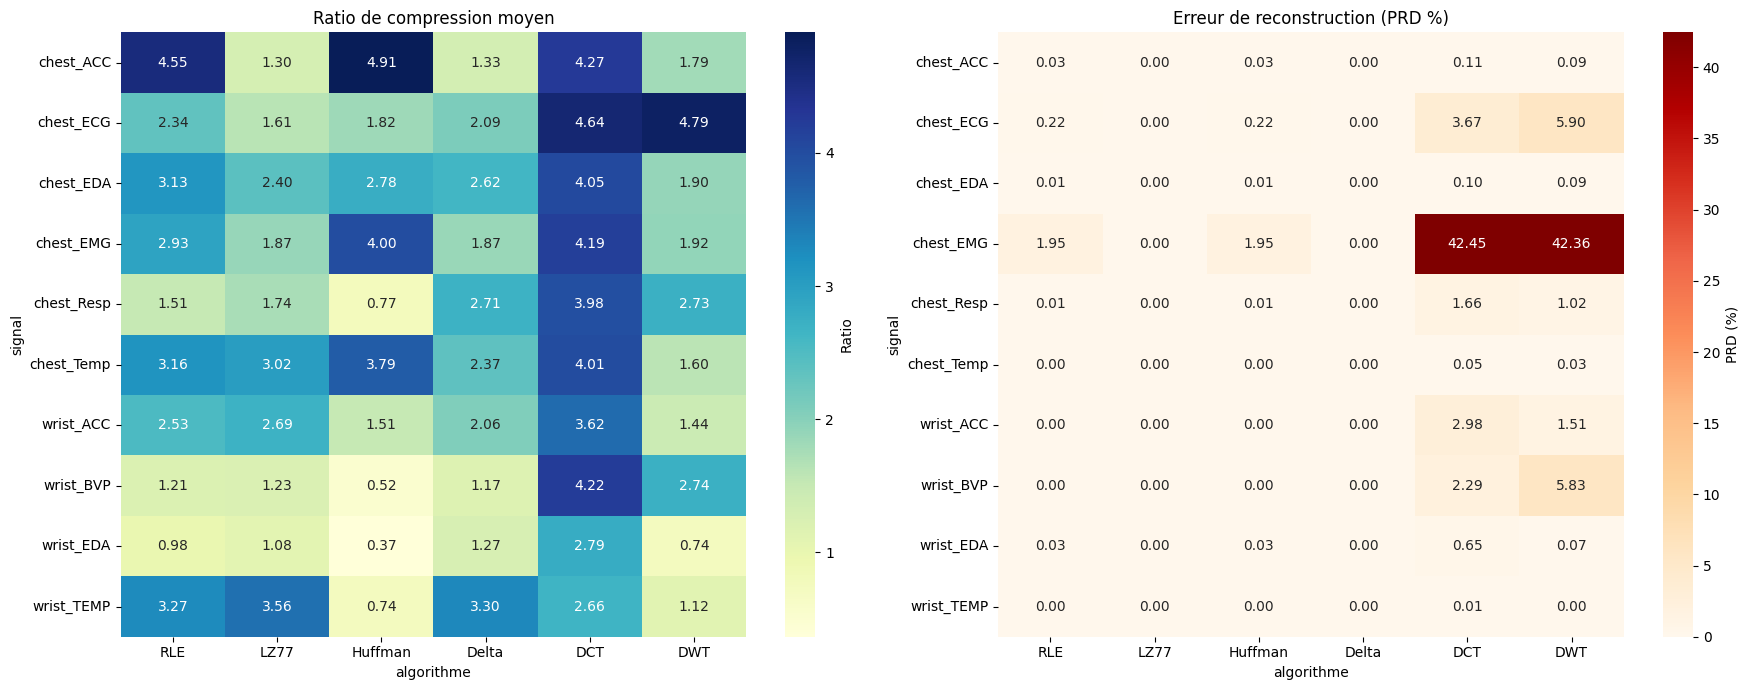

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

pivot_ratio = df_comparaison.pivot(index='signal', columns='algorithme', values='ratio_moyen')[ALGOS]
pivot_prd = df_comparaison.pivot(index='signal', columns='algorithme', values='prd_moyen')[ALGOS]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(pivot_ratio, annot=True, fmt='.2f', cmap='YlGnBu', ax=axes[0], cbar_kws={'label': 'Ratio'})
axes[0].set_title('Ratio de compression moyen')
sns.heatmap(pivot_prd, annot=True, fmt='.2f', cmap='OrRd', ax=axes[1], cbar_kws={'label': 'PRD (%)'})
axes[1].set_title('Erreur de reconstruction (PRD %)')

plt.tight_layout()
os.makedirs(f'{BASE}/4_Results/Figures', exist_ok=True)
plt.savefig(f'{BASE}/4_Results/Figures/heatmap_10signaux_6algos_v5.png', dpi=150, bbox_inches='tight')
plt.show()


## 9bis. Boxplots — dispersion des métriques par algorithme

Les heatmaps ci-dessus montrent des **moyennes**, ce qui masque la variance. Le boxplot
révèle si un algorithme est *constamment* correct ou seulement bon *en moyenne* malgré de
grosses disparités selon le capteur — un argument plus rigoureux pour justifier la sélection
adaptative plutôt qu'un algorithme fixe unique.

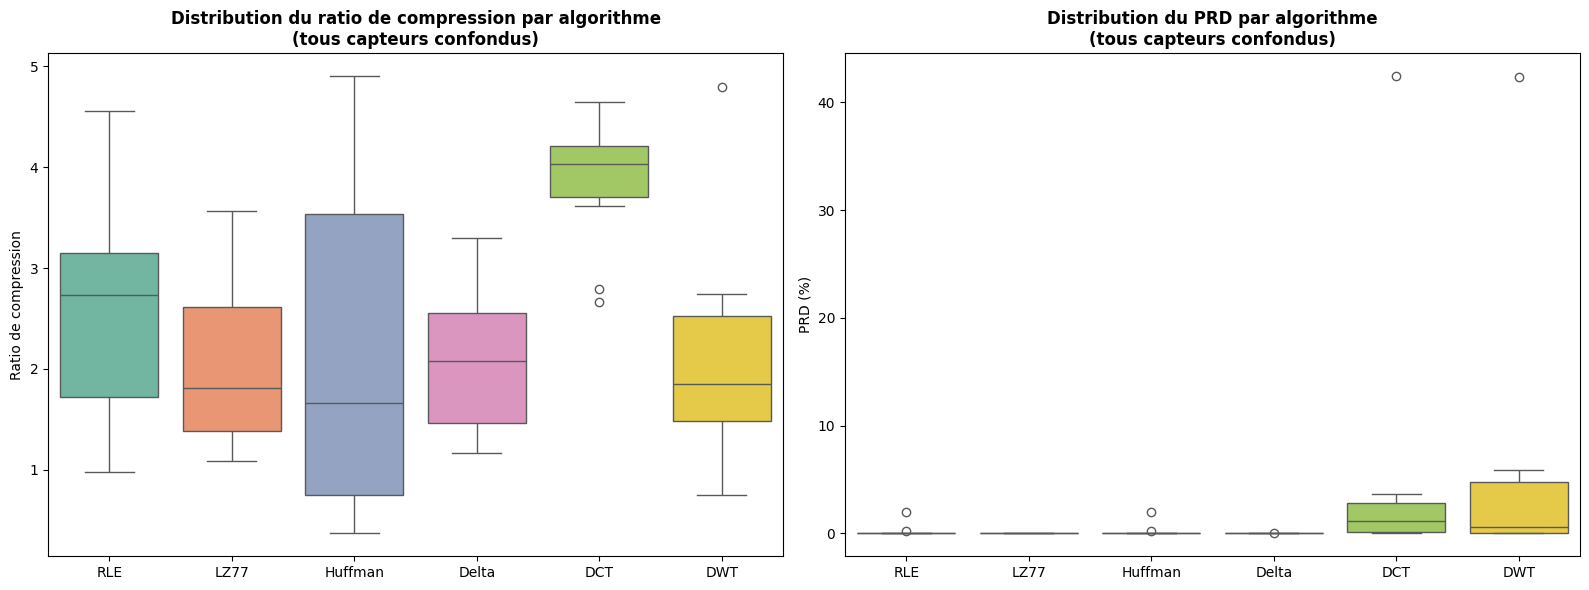

Un algorithme avec une boîte large (grande IQR) est instable selon le capteur :
bon signe pour justifier une sélection dynamique plutôt qu'un choix fixe unique.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

order = ALGOS
sns.boxplot(data=df_comparaison, x='algorithme', y='ratio_moyen', order=order,
            hue='algorithme', palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Distribution du ratio de compression par algorithme\n(tous capteurs confondus)', fontweight='bold')
axes[0].set_xlabel(''); axes[0].set_ylabel('Ratio de compression')

sns.boxplot(data=df_comparaison, x='algorithme', y='prd_moyen', order=order,
            hue='algorithme', palette='Set2', legend=False, ax=axes[1])
axes[1].set_title('Distribution du PRD par algorithme\n(tous capteurs confondus)', fontweight='bold')
axes[1].set_xlabel(''); axes[1].set_ylabel('PRD (%)')

plt.tight_layout()
plt.savefig(f'{BASE}/4_Results/Figures/boxplot_dispersion_algos.png', dpi=150, bbox_inches='tight')
plt.show()

print("Un algorithme avec une boîte large (grande IQR) est instable selon le capteur :")
print("bon signe pour justifier une sélection dynamique plutôt qu'un choix fixe unique.")


## 10. Vérification ciblée : le fix DWT a-t-il marché ?

On vérifie spécifiquement que la PRD de DWT sur les signaux quasi-constants (chest_Temp,
wrist_TEMP) a bien chuté près de 0, preuve que le coefficient d'approximation est maintenant
préservé correctement.

In [ ]:
check = df_comparaison[
    (df_comparaison['algorithme'] == 'DWT') &
    (df_comparaison['signal'].isin(['chest_Temp', 'wrist_TEMP', 'chest_ACC']))
]
print("PRD DWT sur signaux quasi-constants (doit être proche de 0 maintenant) :")
check[['signal', 'ratio_moyen', 'prd_moyen']]


PRD DWT sur signaux quasi-constants (doit être proche de 0 maintenant) :


,signal,ratio_moyen,prd_moyen
5,chest_ACC,1.789986,0.090637
29,chest_Temp,1.598196,0.033219
59,wrist_TEMP,1.123564,0.002011


## 11. Interprétation — résultats centraux du projet

**Preuve du critère SEUIL** : le meilleur algorithme change selon la complexité intrinsèque du
signal (entropie/variance) — DWT/DCT dominent sur les signaux riches en fréquence (ECG),
RLE/Delta dominent sur les signaux stables.

**Preuve du critère TAILLE** : sur `wrist_EDA` et `wrist_TEMP` (segments de seulement 20
échantillons), **Huffman obtient un ratio < 1** (le fichier "compressé" est plus gros que
l'original) — le coût fixe du codebook dépasse l'économie réalisée sur un aussi petit segment.
C'est une preuve empirique directe que la taille du segment doit faire partie du critère de
sélection, comme demandé par le prof.

**Preuve du critère SÉQUENCE** : sera démontrée dans le notebook 03, où le sélecteur compare
chaque segment au précédent dans le flux temporel pour détecter la stabilité locale.

**Conclusion générale** : sur les 10 signaux testés, **aucun algorithme n'est jamais optimal
sur toute la ligne** (regarde la heatmap : la colonne du meilleur ratio change de ligne en ligne)
— c'est la preuve empirique complète qui justifie la sélection adaptative demandée par le
professeur, plutôt qu'un algorithme fixe unique appliqué à tous les capteurs.

## Prochaine étape

`03_Metaheuristique.ipynb` — un algorithme génétique qui apprend automatiquement, à partir de
ces résultats, quel algorithme choisir selon le seuil (entropie/variance), la taille du
segment, et la séquence temporelle.

## 12. Analyse ciblée : effet de la taille du segment (preuve rigoureuse du critère TAILLE)

**Méthodologie** : jusqu'ici, la preuve du critère taille venait de comparer des signaux
*différents* (wrist_EDA vs chest_ECG), ce qui mélange deux facteurs : la taille du segment ET
la nature du signal. Pour isoler proprement l'effet de la **taille seule**, on fixe **un seul
signal** (ECG) et on fait varier **uniquement la durée de la fenêtre** de segmentation
(de 0.02s à 5s). Toute variation de ratio observée ici est donc due à la taille, pas à la
nature du signal.

In [ ]:
window_sizes_sec = [0.02, 0.05, 0.1, 0.5, 1, 2, 5]
raw_ecg = s2_data['signal']['chest']['ECG'].flatten()
fs_ecg = 700

size_rows = []
for w in window_sizes_sec:
    segs_w = segment_signal(raw_ecg, fs_ecg, window_sec=w)
    sample_segs = segs_w[:min(30, len(segs_w))]
    n_samples = int(fs_ecg * w)
    for algo in ALGOS:
        ratios, prds = [], []
        for seg in sample_segs:
            if len(seg) < 2:
                continue
            c, rec = apply_algo(algo, seg)
            ratios.append(compression_ratio(seg, c))
            prds.append(prd(seg, rec))
        if ratios:
            size_rows.append({
                'window_sec': w, 'n_samples': n_samples, 'taille_octets': n_samples * 4,
                'algorithme': algo, 'ratio_moyen': np.mean(ratios), 'prd_moyen': np.mean(prds)
            })

df_taille = pd.DataFrame(size_rows)
os.makedirs(f'{BASE}/4_Results', exist_ok=True)
df_taille.to_csv(f'{BASE}/4_Results/Analyse_effet_taille.csv', index=False)
df_taille


,window_sec,n_samples,taille_octets,algorithme,ratio_moyen,prd_moyen
0,0.02,14,56,RLE,0.871953,4.728943e-01
1,0.02,14,56,LZ77,0.917461,7.457274e-16
2,0.02,14,56,Huffman,0.291852,4.728943e-01
3,0.02,14,56,Delta,0.970939,7.457274e-16
4,0.02,14,56,DCT,2.848624,1.306411e+01
5,0.02,14,56,DWT,0.632456,2.706938e-01
6,0.05,35,140,RLE,1.029650,3.224373e-01
7,0.05,35,140,LZ77,1.034382,9.157530e-16
8,0.05,35,140,Huffman,0.422879,3.224373e-01
9,0.05,35,140,Delta,1.162789,9.157530e-16


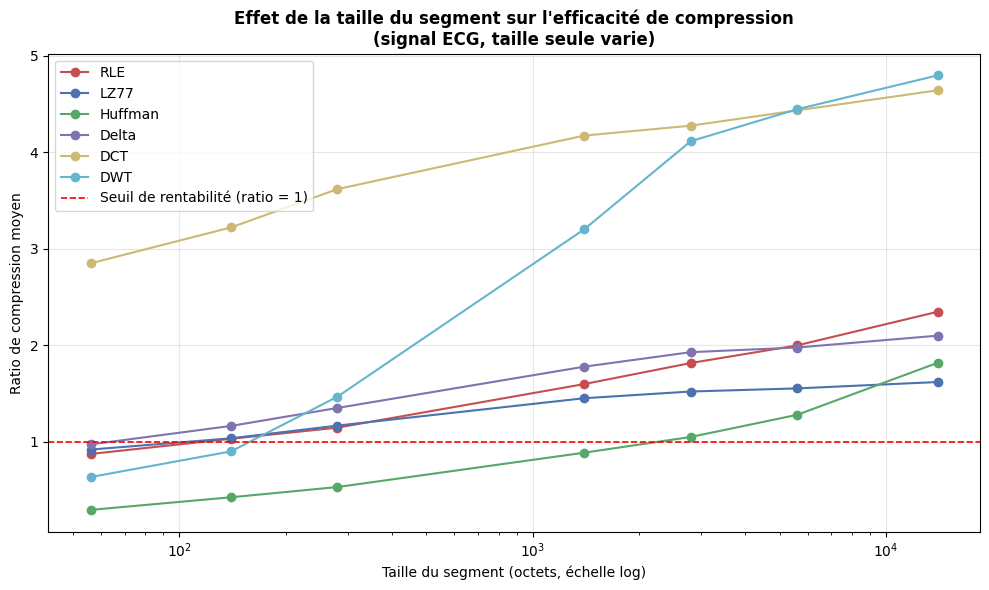

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
colors = {'RLE': '#C44E52', 'LZ77': '#4C72B0', 'Huffman': '#55A868',
          'Delta': '#8172B2', 'DCT': '#CCB974', 'DWT': '#64B5CD'}

for algo in ALGOS:
    sub = df_taille[df_taille['algorithme'] == algo].sort_values('taille_octets')
    ax.plot(sub['taille_octets'], sub['ratio_moyen'], marker='o', label=algo, color=colors[algo])

ax.axhline(1.0, color='red', linestyle='--', linewidth=1.2, label='Seuil de rentabilité (ratio = 1)')
ax.set_xscale('log')
ax.set_xlabel('Taille du segment (octets, échelle log)')
ax.set_ylabel('Ratio de compression moyen')
ax.set_title("Effet de la taille du segment sur l'efficacité de compression\n(signal ECG, taille seule varie)",
             fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{BASE}/4_Results/Figures/effet_taille_segment.png', dpi=150)
plt.show()


## 13. Interprétation de l'analyse taille

Ce qu'il faut chercher dans le graphique ci-dessus :

- **RLE, LZ77, Delta** (pas ou peu d'overhead fixe) devraient rester relativement stables et
  au-dessus de 1 même à petite taille.
- **Huffman** (doit transmettre un codebook entier à chaque segment) devrait chuter fortement,
  voire passer sous 1, aux petites tailles — le coût du codebook dépasse l'économie.
- **DWT/DCT** (métadonnées de formes de coefficients) devraient aussi se dégrader aux petites
  tailles, mais moins brutalement que Huffman.

Si c'est bien ce qu'on observe : c'est la démonstration rigoureuse, toutes choses égales par
ailleurs (même signal, seule la taille varie), que **le critère taille doit conditionner le
choix d'algorithme** — exactement ce que demande le professeur. Ce résultat alimentera
directement la règle "si taille du segment < seuil → algorithme à faible overhead" du
sélecteur multi-critères dans le notebook 03.